# Proyek Analisis Data: E-Commerce Public Dataset (Olist, Brazil)
- **Nama:** [Tazkia Caecaria Marchanda]
- **Email:** [24031554002@mhs.unesa.ac.id]
- **ID Dicoding:** [DS284B6X1713]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Konteks: dataset berisi ±100 ribu pesanan marketplace Olist (Brasil) pada 2016-2018. Agar analisis adil, periode analisis dibatasi pada **Januari 2017 - Agustus 2018** (20 bulan penuh). Tahun 2016 dan September-Oktober 2018 hanya memuat segelintir pesanan sehingga akan menyesatkan jika dimasukkan.

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 10 besar penyumbang revenue (total harga produk, tidak termasuk ongkir) pada pesanan berstatus *delivered* selama Januari 2017 - Agustus 2018, dan berapa persen kontribusinya terhadap total revenue serta rata-rata review score masing-masing, sehingga tim merchandising dapat memprioritaskan stok, promosi, dan perbaikan kualitas kategori?
- **Pertanyaan 2:** Pada periode yang sama, state pelanggan mana yang memiliki rata-rata lama pengiriman dan persentase pesanan terlambat (diterima setelah estimasi) tertinggi, dan seberapa besar keterlambatan menurunkan rata-rata review score, sehingga tim logistik dapat menentukan wilayah prioritas perbaikan pengiriman?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
DATA = 'data/'

## Data Wrangling

### Gathering Data

#### Load seluruh tabel dataset

In [2]:
orders = pd.read_csv(DATA + 'orders_dataset.csv')
customers = pd.read_csv(DATA + 'customers_dataset.csv')
items = pd.read_csv(DATA + 'order_items_dataset.csv')
products = pd.read_csv(DATA + 'products_dataset.csv')
category_tr = pd.read_csv(DATA + 'product_category_name_translation.csv')
reviews = pd.read_csv(DATA + 'order_reviews_dataset.csv')
geo = pd.read_csv(DATA + 'geolocation_dataset.csv')

for name, df in {'orders': orders, 'customers': customers, 'order_items': items, 'products': products,
                 'category_translation': category_tr, 'order_reviews': reviews, 'geolocation': geo}.items():
    print(f'{name:22s} -> {df.shape[0]:>9,} baris, {df.shape[1]} kolom')
orders.head()

orders                 ->    99,441 baris, 8 kolom
customers              ->    99,441 baris, 5 kolom
order_items            ->   112,650 baris, 7 kolom
products               ->    32,951 baris, 9 kolom
category_translation   ->        71 baris, 2 kolom
order_reviews          ->    99,224 baris, 7 kolom
geolocation            -> 1,000,163 baris, 5 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Tujuh tabel dimuat: `orders` (99.441 pesanan), `customers`, `order_items` (112.650 item), `products`, `category_translation`, `order_reviews`, dan `geolocation` (±1 juta baris).
- Relasi antar tabel: `orders.customer_id → customers`, `order_items.order_id → orders`, `order_items.product_id → products → category_translation`, dan `order_reviews.order_id → orders`. Tabel `geolocation` dihubungkan lewat kode pos (*zip code prefix*).
- Kolom tanggal masih terbaca sebagai teks (object), perlu dikonversi pada tahap cleaning.

### Assessing Data

#### Identifying missing value & tipe data

In [3]:
print('Tipe data tabel orders:'); print(orders.dtypes, '\n')
for name, df in {'orders': orders, 'products': products, 'order_reviews': reviews}.items():
    miss = df.isna().sum(); miss = miss[miss > 0]
    print(f'Missing value pada {name}:'); print(miss.to_frame('jumlah').assign(persen=(miss/len(df)*100).round(2)), '\n')

print('Status pesanan:'); print(orders['order_status'].value_counts(), '\n')
delivered = orders[orders['order_status'] == 'delivered']
print('Pesanan delivered tanpa tanggal tiba di pelanggan:', delivered['order_delivered_customer_date'].isna().sum())

Tipe data tabel orders:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object 

Missing value pada orders:
                               jumlah  persen
order_approved_at                 160    0.16
order_delivered_carrier_date     1783    1.79
order_delivered_customer_date    2965    2.98 

Missing value pada products:
                            jumlah  persen
product_category_name          610    1.85
product_name_lenght            610    1.85
product_description_lenght     610    1.85
product_photos_qty             610    1.85
product_weight_g                 2    0.01
product_length_cm                2    0.01
product_height_cm                2    0.01
product_width_cm                 2    0.01 

Missing value pada order_reviews:

#### Identifying duplicate & inconsistent value

In [4]:
print('Duplikat baris penuh -> orders:', orders.duplicated().sum(), '| items:', items.duplicated().sum(), '| geolocation:', geo.duplicated().sum())
print('Order dengan lebih dari satu review:', reviews['order_id'].duplicated().sum(), 'baris review berlebih')

tr_missing = set(products['product_category_name'].dropna()) - set(category_tr['product_category_name'])
print('Kategori tanpa terjemahan bahasa Inggris:', tr_missing)

print('\nJumlah pesanan per bulan (cek kelengkapan periode):')
ts = pd.to_datetime(orders['order_purchase_timestamp'])
print(ts.dt.to_period('M').value_counts().sort_index().loc[lambda s: (s.index < '2017-01') | (s.index > '2018-08')])

Duplikat baris penuh -> orders: 0 | items: 0 | geolocation: 261831
Order dengan lebih dari satu review: 551 baris review berlebih
Kategori tanpa terjemahan bahasa Inggris: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Jumlah pesanan per bulan (cek kelengkapan periode):
order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2018-09     16
2018-10      4
Freq: M, Name: count, dtype: int64


#### Identifying outlier / invalid value (koordinat geolokasi)

In [5]:
# Brasil berada di sekitar lat -34 s.d. 6 dan lng -74 s.d. -34
out_geo = geo[~geo['geolocation_lat'].between(-34, 6) | ~geo['geolocation_lng'].between(-74, -34)]
print('Koordinat di luar wilayah Brasil:', len(out_geo))
print(geo[['geolocation_lat', 'geolocation_lng']].describe().loc[['min', 'max']])

Koordinat di luar wilayah Brasil: 42
     geolocation_lat  geolocation_lng
min           -36.61          -101.47
max            45.07           121.11


**Steps to Take:**
- Konversi seluruh kolom tanggal ke `datetime` (*inaccurate data type*).
- Ambil hanya pesanan `delivered` yang memiliki tanggal tiba, karena lama pengiriman dan keterlambatan hanya valid untuk pesanan yang sudah sampai (*missing value*).
- Batasi periode analisis ke Januari 2017 - Agustus 2018 karena bulan di luar rentang itu tidak lengkap (*invalid/incomplete period*).
- Pada `order_reviews`, simpan satu review terbaru per pesanan agar skor tidak terhitung ganda (*duplicate data*).
- Lengkapi terjemahan 2 kategori yang tidak ada di tabel terjemahan secara manual, dan beri label `unknown` pada produk tanpa kategori (*missing & inconsistent value*).
- Pada `geolocation`, hapus duplikat dan koordinat di luar Brasil (*duplicate & outlier*), lalu rata-ratakan koordinat per kode pos.

**Insight:**
- Missing value pada `orders` terkonsentrasi di kolom tanggal pengiriman: pesanan yang belum/tidak pernah sampai (canceled, unavailable, dll.) memang belum punya tanggal tiba. Hanya 8 pesanan berstatus `delivered` yang tanggal tibanya kosong.
- 610 produk (±1,9%) tidak memiliki kategori, dan 58.247 review (±59%) tidak memiliki komentar teks. Kolom komentar tidak dipakai sehingga dibiarkan.
- `geolocation` sangat redundan: lebih dari 260 ribu baris duplikat, dan ada puluhan titik di luar Brasil.

### Cleaning Data

#### Fixing tipe data, status pesanan, dan periode analisis

In [6]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

n_awal = len(orders)
orders_clean = orders[(orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].notna()].copy()
orders_clean = orders_clean[(orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
                            (orders_clean['order_purchase_timestamp'] < '2018-09-01')]
print(f'Pesanan awal: {n_awal:,} -> setelah cleaning: {len(orders_clean):,}')
print('Missing value tersisa pada kolom kunci:', orders_clean[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].isna().sum().sum())

Pesanan awal: 99,441 -> setelah cleaning: 96,203
Missing value tersisa pada kolom kunci: 0


#### Fixing duplicate review & kategori produk

In [7]:
# Satu review (paling baru) per pesanan
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])
reviews_clean = (reviews.sort_values('review_answer_timestamp')
                        .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
print('Review duplikat per order setelah cleaning:', reviews_clean['order_id'].duplicated().sum())

# Lengkapi terjemahan kategori yang hilang
extra = pd.DataFrame({'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
                      'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers']})
category_full = pd.concat([category_tr, extra], ignore_index=True)

products_clean = products[['product_id', 'product_category_name']].merge(category_full, on='product_category_name', how='left')
products_clean['category'] = products_clean['product_category_name_english'].fillna('unknown')
print('Produk tanpa kategori (label unknown):', (products_clean['category'] == 'unknown').sum())

Review duplikat per order setelah cleaning: 0
Produk tanpa kategori (label unknown): 610


#### Fixing geolocation (duplikat & outlier koordinat)

In [8]:
geo_clean = geo.drop_duplicates()
geo_clean = geo_clean[geo_clean['geolocation_lat'].between(-34, 6) & geo_clean['geolocation_lng'].between(-74, -34)]
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean().reset_index())
print(f'Geolocation: {len(geo):,} -> {len(geo_clean):,} baris -> {len(geo_zip):,} kode pos unik')

Geolocation: 1,000,163 -> 738,299 baris -> 19,010 kode pos unik


#### Menggabungkan tabel menjadi dataset utama & membuat fitur baru

In [9]:
main_df = (orders_clean
           .merge(customers[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id', how='inner')
           .merge(items[['order_id', 'order_item_id', 'product_id', 'price', 'freight_value']], on='order_id', how='inner')
           .merge(products_clean[['product_id', 'category']], on='product_id', how='left')
           .merge(reviews_clean, on='order_id', how='left'))
main_df['category'] = main_df['category'].fillna('unknown')

# Fitur: lama pengiriman (hari) & status keterlambatan
main_df['delivery_days'] = (main_df['order_delivered_customer_date'] - main_df['order_purchase_timestamp']).dt.total_seconds() / 86400
main_df['is_late'] = main_df['order_delivered_customer_date'] > main_df['order_estimated_delivery_date']
main_df['order_month'] = main_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print('Ukuran main_df:', main_df.shape, '| order unik:', main_df['order_id'].nunique())
print('Review kosong (order tanpa review):', main_df['review_score'].isna().sum(), 'baris')
main_df[['order_id', 'customer_state', 'category', 'price', 'delivery_days', 'is_late', 'review_score']].head()

Ukuran main_df: (109872, 20) | order unik: 96203
Review kosong (order tanpa review): 823 baris


,order_id,customer_state,category,price,delivery_days,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,housewares,29.99,8.44,False,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,BA,perfumery,118.70,13.78,False,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,GO,auto,159.90,9.39,False,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,pet_shop,45.00,13.21,False,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,stationery,19.90,2.87,False,5.00


**Insight:**
- Setelah cleaning tersisa **96.203 pesanan** (109.872 baris item) pada periode Jan 2017 - Agu 2018, berstatus *delivered*, lengkap dengan tanggal tiba.
- Dua fitur baru dibuat: `delivery_days` (tanggal tiba − tanggal pembelian) dan `is_late` (tiba setelah estimasi).
- `main_df` berada di level **item pesanan**: untuk metrik per pesanan (lama kirim, review) data harus di-*drop duplicate* berdasarkan `order_id` agar tidak terhitung berulang.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik & tren bulanan

In [10]:
order_df = main_df.drop_duplicates('order_id')   # 1 baris = 1 pesanan

print('Ringkasan statistik (level pesanan):')
print(order_df[['delivery_days', 'review_score']].describe().T)
print('\nRingkasan statistik (level item):')
print(main_df[['price', 'freight_value']].describe().T)

monthly = main_df.groupby('order_month').agg(revenue=('price', 'sum'), orders=('order_id', 'nunique'))
monthly['revenue_mom_%'] = monthly['revenue'].pct_change() * 100
print('\nTren bulanan:'); monthly

Ringkasan statistik (level pesanan):
                  count  mean  std  min  25%   50%   75%    max
delivery_days 96,203.00 12.54 9.53 0.53 6.76 10.21 15.68 209.63
review_score  95,560.00  4.16 1.28 1.00 4.00  5.00  5.00   5.00

Ringkasan statistik (level item):
                   count   mean    std  min   25%   50%    75%      max
price         109,872.00 119.96 182.35 0.85 39.90 74.90 134.04 6,735.00
freight_value 109,872.00  19.95  15.70 0.00 13.08 16.26  21.15   409.68

Tren bulanan:


,revenue,orders,revenue_mom_%
order_month,,,
2017-01,"111,798.36",750,NaN
2017-02,"234,223.40",1653,109.51
2017-03,"359,198.85",2546,53.36
2017-04,"340,669.68",2303,-5.16
2017-05,"489,159.25",3545,43.59
2017-06,"421,923.37",3135,-13.75
2017-07,"481,604.52",3872,14.15
2017-08,"554,699.70",4193,15.18
2017-09,"607,399.67",4150,9.50


### Explore kategori produk (Pertanyaan 1)

In [11]:
cat_summary = (main_df.groupby('category')
              .agg(revenue=('price', 'sum'), items_sold=('order_item_id', 'size'),
                   orders=('order_id', 'nunique'), avg_review=('review_score', 'mean'))
              .sort_values('revenue', ascending=False))
cat_summary['revenue_share_%'] = cat_summary['revenue'] / cat_summary['revenue'].sum() * 100
cat_summary['cum_share_%'] = cat_summary['revenue_share_%'].cumsum()
print('Total kategori:', len(cat_summary), '| Total revenue:', f"{cat_summary['revenue'].sum():,.0f}")
print('\n10 kategori teratas:'); display(cat_summary.head(10))
print('5 kategori terbawah:'); display(cat_summary.tail(5))

Total kategori: 74 | Total revenue: 13,179,778

10 kategori teratas:


,revenue,items_sold,orders,avg_review,revenue_share_%,cum_share_%
category,,,,,,
health_beauty,"1,229,557.50",9422,8610,4.19,9.33,9.33
watches_gifts,"1,163,187.91",5853,5489,4.07,8.83,18.15
bed_bath_table,"1,022,955.77",10945,9267,3.92,7.76,25.92
sports_leisure,"952,661.40",8413,7512,4.16,7.23,33.14
computers_accessories,"887,944.60",7631,6517,3.99,6.74,39.88
furniture_decor,"706,237.17",8095,6258,3.96,5.36,45.24
housewares,"614,341.62",6783,5734,4.11,4.66,49.90
cool_stuff,"609,158.00",3711,3552,4.20,4.62,54.52
auto,"577,721.09",4131,3801,4.12,4.38,58.91


5 kategori terbawah:


,revenue,items_sold,orders,avg_review,revenue_share_%,cum_share_%
category,,,,,,
flowers,"1,110.04",33,29,4.42,0.01,99.98
home_comfort_2,760.27,30,24,3.63,0.01,99.99
cds_dvds_musicals,730.00,14,12,4.64,0.01,99.99
fashion_childrens_clothes,519.95,7,7,5.00,0.00,100.00
security_and_services,283.29,2,2,2.50,0.00,100.00


**Insight:**
- Terdapat 74 kategori dengan total revenue R$ 13,18 juta. Revenue sangat terkonsentrasi: **10 kategori teratas menyumbang 62,5%** dan 5 teratas hampir 40%.
- `health_beauty` memimpin (R$ 1,23 juta; 9,3%), disusul `watches_gifts` (8,8%) dan `bed_bath_table` (7,8%).
- `bed_bath_table` adalah kategori dengan **item terjual terbanyak (10.945)** tetapi revenue-nya hanya peringkat 3, artinya harga per item relatif rendah. Sebaliknya `watches_gifts` hanya terjual 5.853 item namun revenue peringkat 2 (harga per item tinggi).
- Ekor bawah sangat tipis: kategori seperti `security_and_services` hanya 2 item (R$ 283), sehingga skor reviewnya (2,50) tidak representatif.

### Explore pengiriman per state & hubungannya dengan review (Pertanyaan 2)

In [12]:
state_summary = (order_df.groupby('customer_state')
                .agg(orders=('order_id', 'size'), avg_delivery_days=('delivery_days', 'mean'),
                     late_pct=('is_late', 'mean'), avg_review=('review_score', 'mean')))
state_summary['late_pct'] *= 100
state_summary = state_summary.sort_values('orders', ascending=False)

nat_late = order_df['is_late'].mean() * 100
print(f'Rata-rata nasional: lama kirim {order_df.delivery_days.mean():.1f} hari | terlambat {nat_late:.1f}% | review {order_df.review_score.mean():.2f}')
print('\nTop 10 state berdasarkan % terlambat (minimal 300 pesanan):')
display(state_summary[state_summary['orders'] >= 300].sort_values('late_pct', ascending=False).head(10))

print('Review score: tepat waktu vs terlambat')
display(order_df.groupby('is_late').agg(orders=('order_id', 'size'), avg_review=('review_score', 'mean'), avg_delivery_days=('delivery_days', 'mean')))
print('Korelasi lama kirim vs review score:', round(order_df[['delivery_days', 'review_score']].corr().iloc[0, 1], 3))

Rata-rata nasional: lama kirim 12.5 hari | terlambat 8.1% | review 4.16

Top 10 state berdasarkan % terlambat (minimal 300 pesanan):


,orders,avg_delivery_days,late_pct,avg_review
customer_state,,,,
AL,396,24.52,23.99,3.85
MA,713,21.54,19.64,3.83
PI,475,19.44,16.00,3.99
CE,1273,21.24,15.40,3.94
SE,332,21.44,15.36,3.90
BA,3253,19.33,14.05,3.93
RJ,12310,15.30,13.52,3.97
PA,942,23.76,12.42,3.91
ES,1992,15.78,12.25,4.08


Review score: tepat waktu vs terlambat


,orders,avg_review,avg_delivery_days
is_late,,,
False,88381,4.29,10.86
True,7822,2.57,31.50


Korelasi lama kirim vs review score: -0.334


**Insight:**
- Rata-rata nasional: lama kirim **12,5 hari**, **8,1%** pesanan terlambat, review 4,16.
- State dengan keterlambatan tertinggi (minimal 300 pesanan) adalah **AL (24,0%)**, **MA (19,6%)**, PI (16,0%), CE (15,4%) dan SE (15,4%), semuanya di wilayah Timur Laut, dengan rata-rata lama kirim 19-25 hari. **RJ** (13,5%) dan **BA** (14,0%) juga tinggi dan memiliki volume besar (12.310 dan 3.253 pesanan).
- Pesanan terlambat mendapat review rata-rata **2,57**, jauh di bawah **4,29** untuk pesanan tepat waktu (selisih 1,73 poin). Korelasi lama kirim terhadap review score negatif (-0,33).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

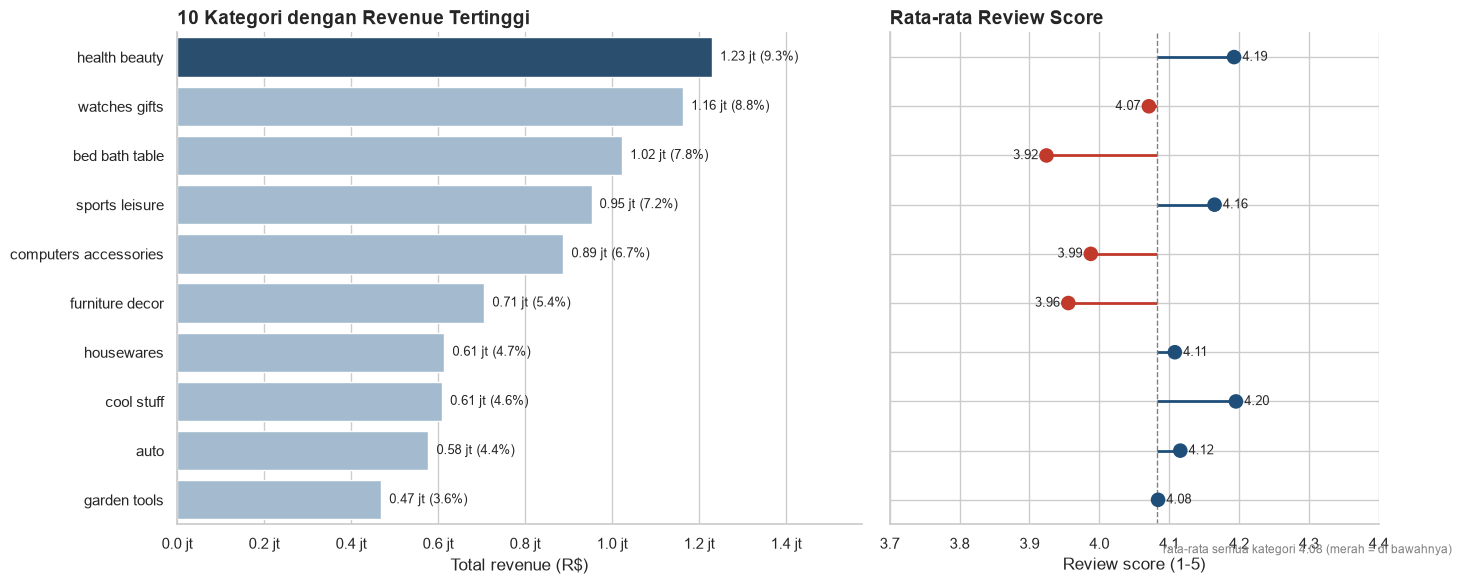

In [13]:
top10 = cat_summary.head(10).reset_index()
top10['label'] = top10['category'].str.replace('_', ' ')
colors = ['#1f4e79'] + ['#9dbbd6'] * 9          # sorot kategori #1

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})
sns.barplot(data=top10, y='label', x='revenue', palette=colors, ax=axes[0])
axes[0].set_title('10 Kategori dengan Revenue Tertinggi', fontsize=14, loc='left', fontweight='bold')
axes[0].set_xlabel('Total revenue (R$)'); axes[0].set_ylabel('')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.1f} jt'))
for i, (rev, share) in enumerate(zip(top10['revenue'], top10['revenue_share_%'])):
    axes[0].text(rev, i, f'  {rev/1e6:.2f} jt ({share:.1f}%)', va='center', fontsize=9)
axes[0].set_xlim(0, top10['revenue'].max() * 1.28)

avg_all = main_df['review_score'].mean()
# Dot plot (bukan bar) agar sumbu tidak perlu dimulai dari nol tanpa menyesatkan
y = np.arange(len(top10))
rev_colors = ['#c0392b' if s < avg_all else '#1f4e79' for s in top10['avg_review']]
axes[1].hlines(y, avg_all, top10['avg_review'], color=rev_colors, lw=2)
axes[1].scatter(top10['avg_review'], y, c=rev_colors, s=90, zorder=3)
axes[1].axvline(avg_all, color='gray', ls='--', lw=1)
axes[1].set_yticks(y); axes[1].set_yticklabels([]); axes[1].set_ylim(len(top10) - 0.5, -0.5)
axes[1].set_xlim(3.7, 4.4)
axes[1].set_title('Rata-rata Review Score', fontsize=14, loc='left', fontweight='bold')
axes[1].set_xlabel('Review score (1-5)')
axes[1].text(avg_all, len(top10) - 0.1, f'  rata-rata semua kategori {avg_all:.2f} (merah = di bawahnya)', fontsize=8.5, color='gray', va='top')
for i, sc_ in enumerate(top10['avg_review']):
    axes[1].text(sc_ + (0.012 if sc_ >= avg_all else -0.012), i, f'{sc_:.2f}', va='center',
                 ha='left' if sc_ >= avg_all else 'right', fontsize=9)
sns.despine(); plt.tight_layout(); plt.show()

**Insight Pertanyaan 1:**
- Sepuluh kategori teratas menyumbang **62,5%** revenue. Lima teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang 39,9%, dan `health_beauty` menjadi kategori no. 1 dengan R$ 1,23 juta (9,3%).
- Empat kategori besar memiliki review **di bawah rata-rata** semua kategori (4,08): `bed_bath_table` (3,92), `furniture_decor` (3,96), `computers_accessories` (3,99), dan `watches_gifts` (4,07). `bed_bath_table` paling mendesak karena juga kategori dengan volume item tertinggi.
- Kategori dengan revenue besar sekaligus review baik, yaitu `health_beauty` (4,19), `cool_stuff` (4,20), dan `sports_leisure` (4,16), layak menjadi prioritas promosi.

### Pertanyaan 2:

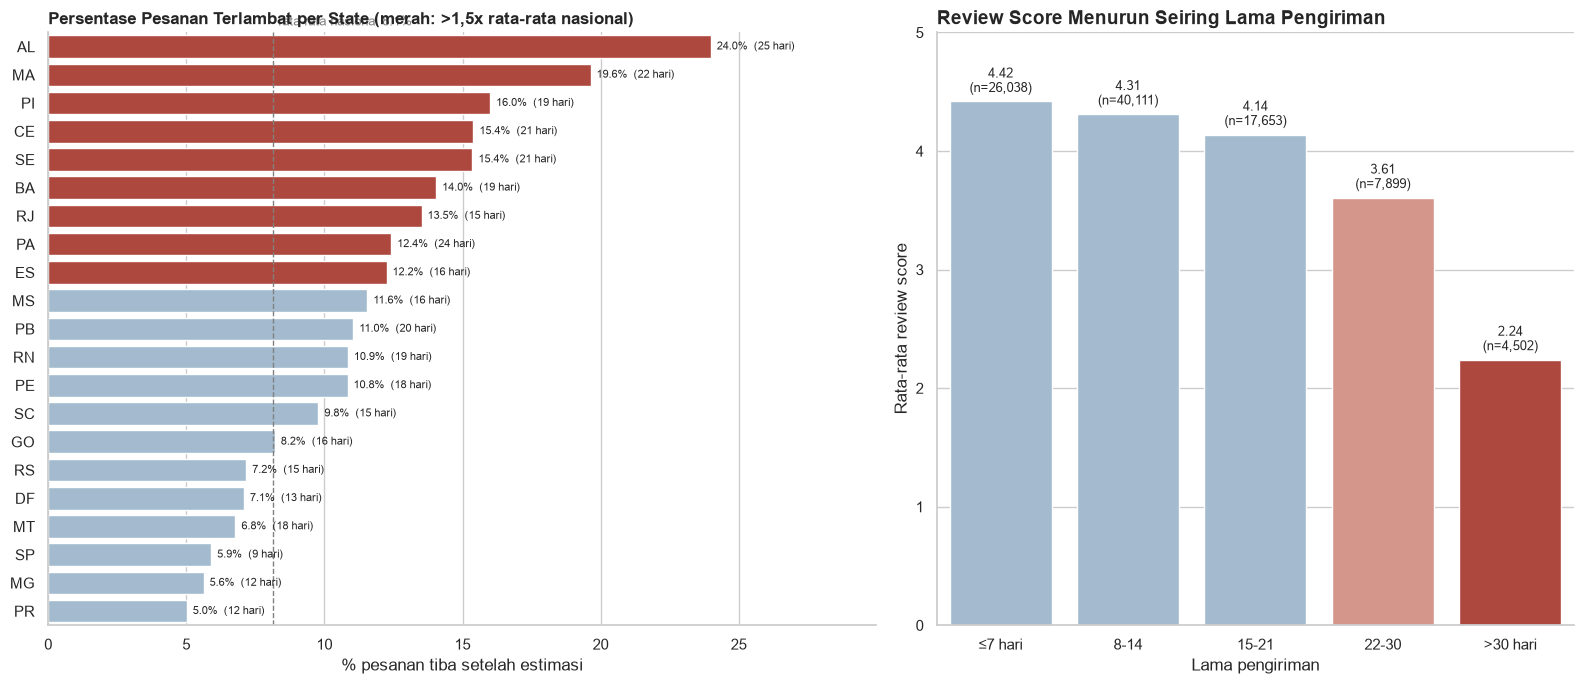

In [14]:
plot_state = state_summary[state_summary['orders'] >= 300].sort_values('late_pct', ascending=False).reset_index()
bar_colors = ['#c0392b' if v > nat_late * 1.5 else '#9dbbd6' for v in plot_state['late_pct']]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.3, 1]})
sns.barplot(data=plot_state, y='customer_state', x='late_pct', palette=bar_colors, ax=axes[0])
axes[0].axvline(nat_late, color='gray', ls='--', lw=1)
axes[0].text(nat_late + 0.2, -0.75, f'rata-rata nasional {nat_late:.1f}%', color='gray', fontsize=9)
axes[0].set_title('Persentase Pesanan Terlambat per State (merah: >1,5x rata-rata nasional)', fontsize=12, loc='left', fontweight='bold')
axes[0].set_xlabel('% pesanan tiba setelah estimasi'); axes[0].set_ylabel('')
for i, (late, d) in enumerate(zip(plot_state['late_pct'], plot_state['avg_delivery_days'])):
    axes[0].text(late, i, f'  {late:.1f}%  ({d:.0f} hari)', va='center', fontsize=8)
axes[0].set_xlim(0, plot_state['late_pct'].max() * 1.25)

order_df = order_df.copy()
order_df['delivery_bin'] = pd.cut(order_df['delivery_days'], [0, 7, 14, 21, 30, np.inf],
                                  labels=['≤7 hari', '8-14', '15-21', '22-30', '>30 hari'])
bin_summary = order_df.groupby('delivery_bin', observed=True).agg(orders=('order_id', 'size'), avg_review=('review_score', 'mean')).reset_index()
sns.barplot(data=bin_summary, x='delivery_bin', y='avg_review',
            palette=['#9dbbd6', '#9dbbd6', '#9dbbd6', '#e08e7f', '#c0392b'], ax=axes[1])
axes[1].set_ylim(0, 5); axes[1].set_title('Review Score Menurun Seiring Lama Pengiriman', fontsize=14, loc='left', fontweight='bold')
axes[1].set_xlabel('Lama pengiriman'); axes[1].set_ylabel('Rata-rata review score')
for i, (s, n) in enumerate(zip(bin_summary['avg_review'], bin_summary['orders'])):
    axes[1].text(i, s + 0.08, f'{s:.2f}\n(n={n:,})', ha='center', fontsize=9)
sns.despine(); plt.tight_layout(); plt.show()

**Insight Pertanyaan 2:**
- Keterlambatan sangat tidak merata: state di Timur Laut dan RJ jauh di atas rata-rata nasional 8,1%, dengan **AL 24,0%** dan **MA 19,6%** terburuk. SP, MG, dan PR (basis logistik di Tenggara/Selatan) hanya 5-6%, dengan lama kirim 9-12 hari.
- Review score turun tajam seiring lama pengiriman: **4,42 (≤7 hari)** → 4,14 (15-21 hari) → **3,61 (22-30 hari)** → **2,24 (>30 hari)**. Penurunan paling curam terjadi setelah hari ke-21.
- Sekitar 12,9% pesanan (12.387 pesanan) memakan waktu lebih dari 21 hari dan menjadi sumber utama ulasan buruk.

## Analisis Lanjutan (Opsional)

### RFM Analysis
**Tujuan:** mengelompokkan pelanggan (`customer_unique_id`) berdasarkan perilaku belanja agar tim CRM dapat menyusun kampanye yang tepat sasaran.
- **Recency**: hari sejak pembelian terakhir (dihitung dari 1 hari setelah tanggal pembelian terakhir pada dataset).
- **Frequency**: jumlah pesanan unik. **Monetary**: total belanja (harga produk + ongkir).
- Skor R dan M diberi 1-4 berdasarkan kuartil, skor F dibuat manual (1 pesanan = 1, 2 pesanan = 2, ≥3 pesanan = 3) karena sebagian besar pelanggan hanya membeli sekali. Segmen ditentukan lewat aturan bisnis (*manual grouping*, tanpa machine learning).

In [15]:
snapshot = main_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
rfm = (main_df.groupby('customer_unique_id')
       .agg(last_order=('order_purchase_timestamp', 'max'), frequency=('order_id', 'nunique'),
            monetary=('price', 'sum'), freight=('freight_value', 'sum')))
rfm['monetary'] += rfm.pop('freight')
rfm['recency'] = (snapshot - rfm.pop('last_order')).dt.days

rfm['R'] = pd.qcut(rfm['recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)   # makin baru, skor makin tinggi
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['F'] = rfm['frequency'].clip(upper=3)

def segment(r):
    if r['F'] >= 2:                         return 'Repeat Buyer'
    if r['R'] >= 3 and r['M'] >= 3:         return 'Recent Big Spender'
    if r['R'] >= 3:                         return 'Recent One-time'
    if r['M'] >= 3:                         return 'Lapsed Big Spender'
    return 'Lapsed Low Value'
rfm['segment'] = rfm.apply(segment, axis=1)

seg = (rfm.groupby('segment').agg(customers=('recency', 'size'), avg_recency=('recency', 'mean'),
                                  avg_frequency=('frequency', 'mean'), avg_monetary=('monetary', 'mean'),
                                  total_monetary=('monetary', 'sum')).sort_values('customers', ascending=False))
seg['customer_%'] = seg['customers'] / seg['customers'].sum() * 100
seg['revenue_%'] = seg['total_monetary'] / seg['total_monetary'].sum() * 100
seg

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_%,revenue_%
segment,,,,,,,
Lapsed Low Value,23622,362.45,1.00,63.79,"1,506,932.32",25.37,9.80
Recent One-time,22592,111.52,1.00,63.00,"1,423,377.11",24.27,9.26
Recent Big Spender,22422,111.40,1.00,261.18,"5,856,156.94",24.08,38.10
Lapsed Big Spender,21671,362.01,1.00,264.17,"5,724,741.53",23.28,37.24
Repeat Buyer,2789,219.60,2.11,308.55,"860,533.19",3.00,5.60


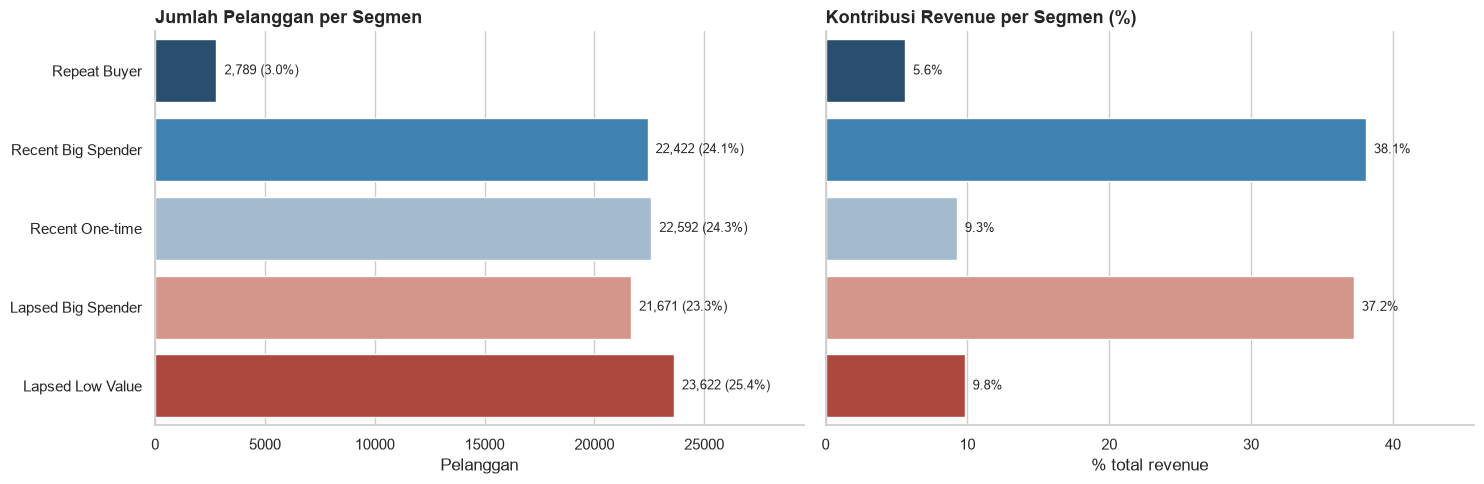

In [16]:
order_seg = ['Repeat Buyer', 'Recent Big Spender', 'Recent One-time', 'Lapsed Big Spender', 'Lapsed Low Value']
seg_plot = seg.reindex(order_seg).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = ['#1f4e79', '#2e86c1', '#9dbbd6', '#e08e7f', '#c0392b']
sns.barplot(data=seg_plot, x='customers', y='segment', palette=palette, ax=axes[0])
axes[0].set_title('Jumlah Pelanggan per Segmen', fontsize=13, loc='left', fontweight='bold'); axes[0].set_xlabel('Pelanggan'); axes[0].set_ylabel('')
for i, (n, p) in enumerate(zip(seg_plot['customers'], seg_plot['customer_%'])): axes[0].text(n, i, f'  {n:,} ({p:.1f}%)', va='center', fontsize=9)
axes[0].set_xlim(0, seg_plot['customers'].max() * 1.25)
sns.barplot(data=seg_plot, x='revenue_%', y='segment', palette=palette, ax=axes[1])
axes[1].set_title('Kontribusi Revenue per Segmen (%)', fontsize=13, loc='left', fontweight='bold'); axes[1].set_xlabel('% total revenue'); axes[1].set_ylabel(''); axes[1].set_yticklabels([])
for i, p in enumerate(seg_plot['revenue_%']): axes[1].text(p, i, f'  {p:.1f}%', va='center', fontsize=9)
axes[1].set_xlim(0, seg_plot['revenue_%'].max() * 1.2)
sns.despine(); plt.tight_layout(); plt.show()

**Insight RFM:**
- Dari 93.096 pelanggan unik, **hanya 3,0% (2.789) yang pernah repeat order**; sisanya (97%) hanya membeli satu kali. Retensi pelanggan adalah titik lemah terbesar.
- **Recent Big Spender** (24,1% pelanggan) dan **Lapsed Big Spender** (23,3% pelanggan) masing-masing menyumbang sekitar 38% dan 37% revenue. Pelanggan dengan nilai belanja besar namun sudah lama tidak kembali (rata-rata 362 hari sejak transaksi terakhir) adalah potensi win-back yang besar.
- Segmen `Lapsed Low Value` dan `Recent One-time` bernilai kecil (rata-rata sekitar R$ 63) dan hanya menyumbang sekitar 9-10% revenue per segmen.

### Geospatial Analysis
**Tujuan:** melihat pola sebaran geografis pelanggan dan kualitas pengiriman. Koordinat pelanggan diperoleh dengan menggabungkan `customer_zip_code_prefix` dengan rata-rata koordinat per kode pos (`geo_zip`). Titik diwarnai berdasarkan rata-rata lama pengiriman, sehingga wilayah dengan pengiriman lambat terlihat jelas.

14,733 kode pos pelanggan berhasil dipetakan


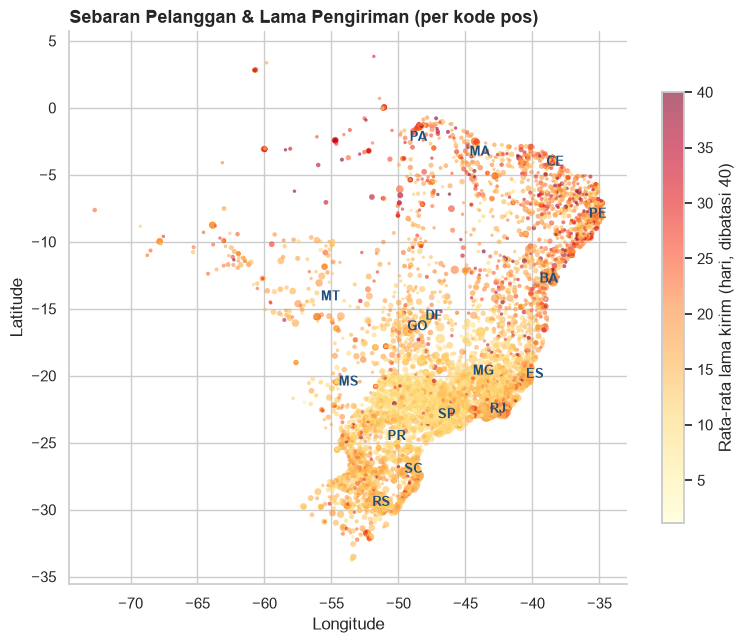

In [17]:
zip_df = (order_df.merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='inner')
          .groupby('customer_zip_code_prefix')
          .agg(lat=('geolocation_lat', 'first'), lng=('geolocation_lng', 'first'),
               orders=('order_id', 'size'), avg_days=('delivery_days', 'mean')).reset_index())
print(f'{len(zip_df):,} kode pos pelanggan berhasil dipetakan')

state_geo = (customers.merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix')
             .groupby('customer_state')[['geolocation_lat', 'geolocation_lng']].mean()
             .rename(columns={'geolocation_lat': 'lat', 'geolocation_lng': 'lng'}).reset_index())

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(zip_df['lng'], zip_df['lat'], c=zip_df['avg_days'].clip(upper=40), s=np.sqrt(zip_df['orders']) * 6,
                cmap='YlOrRd', alpha=0.6, edgecolor='none')
plt.colorbar(sc, ax=ax, shrink=0.7, label='Rata-rata lama kirim (hari, dibatasi 40)')
sg = state_geo.merge(state_summary.reset_index()[['customer_state', 'orders']], on='customer_state')
for _, r in sg[sg['orders'] >= 700].iterrows():
    ax.annotate(r['customer_state'], (r['lng'], r['lat']), fontsize=9, fontweight='bold', color='#1f4e79')
ax.set_title('Sebaran Pelanggan & Lama Pengiriman (per kode pos)', fontsize=13, loc='left', fontweight='bold')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_aspect('equal'); sns.despine(); plt.show()

**Insight Geospatial:**
- Pelanggan sangat terkonsentrasi di koridor Tenggara-Selatan (SP, RJ, MG, PR, RS, SC) yang menyumbang mayoritas titik padat. SP, RJ, dan MG saja mencakup sekitar 66% pesanan.
- Warna kuning (pengiriman ≤ 15 hari) mendominasi sekitar SP, MG, dan PR, sedangkan titik oranye-merah (> 20 hari) menumpuk di pesisir Timur Laut (BA, PE, CE, MA) dan wilayah Amazon/Utara (PA). Pola jarak dari pusat penjual (SP) berbanding lurus dengan lama pengiriman.
- Wilayah Utara dan Timur Laut memiliki volume kecil tetapi pengiriman terlama, sehingga efisiensi dapat ditingkatkan lewat gudang/hub regional.

### Binning: Segmentasi Lama Pengiriman
**Tujuan:** mengelompokkan pesanan ke dalam 5 kelompok lama pengiriman (≤7, 8-14, 15-21, 22-30, >30 hari) dengan `pd.cut`, lalu membandingkan review score tiap kelompok (divisualisasikan pada bagian Pertanyaan 2).

In [18]:
bin_summary['share_%'] = bin_summary['orders'] / bin_summary['orders'].sum() * 100
bin_summary

,delivery_bin,orders,avg_review,share_%
0,≤7 hari,26038,4.42,27.07
1,8-14,40111,4.31,41.69
2,15-21,17653,4.14,18.35
3,22-30,7899,3.61,8.21
4,>30 hari,4502,2.24,4.68


**Insight Binning:**
- 68,8% pesanan tiba dalam ≤14 hari dengan review di atas 4,3, sedangkan **12,9%** pesanan (>21 hari) mendapat review rata-rata di bawah 3,7.
- Kelompok >30 hari hanya 4,7% pesanan, namun reviewnya hanya 2,24, sehingga menjaga pengiriman di bawah 21 hari adalah target yang masuk akal.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Jan 2017 - Agu 2018, **10 kategori teratas menyumbang 62,5% revenue (R$ 8,2 juta dari R$ 13,2 juta)**, dipimpin `health_beauty` (R$ 1,23 juta, 9,3%), `watches_gifts` (8,8%), dan `bed_bath_table` (7,8%). Namun empat dari sepuluh kategori teratas memiliki review di bawah rata-rata 4,08: `bed_bath_table` (3,92), `furniture_decor` (3,96), `computers_accessories` (3,99), dan `watches_gifts` (4,07).
- **Conclusion pertanyaan 2:** Rata-rata lama kirim nasional 12,5 hari dengan **8,1%** pesanan terlambat. Keterlambatan tertinggi di **AL (24,0%)**, **MA (19,6%)**, PI, CE, SE, BA, dan RJ (13,5% dengan volume 12.310 pesanan), sedangkan SP, MG, dan PR hanya 5-6%. Keterlambatan menurunkan review dari **4,29 menjadi 2,57**, dan pesanan yang tiba >30 hari hanya mendapat 2,24.

**Rekomendasi Action Item:**
- **Prioritaskan promosi dan stok** pada `health_beauty`, `cool_stuff`, dan `sports_leisure`: revenue besar dengan review di atas rata-rata.
- **Audit kualitas** `bed_bath_table`, `furniture_decor`, dan `computers_accessories` (volume besar, review di bawah rata-rata): tinjau ulasan negatif, kualitas produk, kesesuaian deskripsi, dan penjual dengan skor terendah.
- **Perbaiki logistik di Timur Laut** (AL, MA, PI, CE, SE, BA) dan **RJ** (volume besar): tambah hub/gudang regional, renegosiasi mitra kurir, dan sesuaikan estimasi pengiriman agar lebih realistis. Target: pesanan terlambat di bawah rata-rata nasional 8,1% dan pengiriman maksimal 21 hari.
- **Program retensi:** kirim kampanye win-back ke segmen *Lapsed Big Spender* (±21 ribu pelanggan) dan tawarkan voucher pembelian kedua ke *Recent Big Spender* untuk menaikkan repeat order dari 3%.

---
### Ekspor Data untuk Dashboard

In [19]:
export_cols = ['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp', 'order_item_id',
               'category', 'price', 'freight_value', 'review_score', 'delivery_days', 'is_late']
export = main_df[export_cols].copy()
export['delivery_days'] = export['delivery_days'].round(2)
export.to_csv('dashboard/main_data.csv', index=False)
state_geo.round(4).to_csv('dashboard/state_geo.csv', index=False)
print('main_data.csv:', export.shape, '| state_geo.csv:', state_geo.shape)

main_data.csv: (109872, 11) | state_geo.csv: (27, 3)
